<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Who enters a finishing comparison when the minutes threshold changes?

Compare observed goals with American Soccer Analysis expected goals for the **2025 MLS regular season**, then normalize both by minutes played. A minutes threshold changes which player-team lines enter the comparison; it does not change the underlying shots or establish a player’s enduring finishing skill.

**Recorded public data, not synthetic observations.** Three original ASA responses contain shooting metrics and the player/team name directories. The real published worker reads these captures through its supported local API override. An explicit live mode queries ASA without fallback. Directories and statistics were retrieved separately, not as an atomic snapshot.

**Data: [American Soccer Analysis](https://www.americansocceranalysis.com/), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).** Bundled data and derived tables/charts remain under that license; see [data attribution](fixtures/LICENSE.md) and [capture provenance](fixtures/provenance.json).

## Choose a minimum exposure

`MIN_MINUTES` is a whole number from **90 through 2,500 minutes**, default **900**. The experiment raises it to **1,800**. This is a threshold for each **player-team line**, so a traded player can have separate lines and may qualify for one team but not another. We do not combine transfers into a full-season player ranking.

`DATA_MODE` is **`recorded`** or **`live`**. Both request 2025 MLS regular-season data with the worker’s upstream minimum set to zero, then apply the analytical cutoff in visible SQL. Restart and run all after editing.

In [1]:
MIN_MINUTES = 900
DATA_MODE = "recorded"

In [2]:
import json
from datetime import UTC, datetime
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from notebook_support import finish, theme
from recorded_api import AsaSource

assert type(MIN_MINUTES) is int and 90 <= MIN_MINUTES <= 2500
assert DATA_MODE in {"recorded", "live"}
RUN_UTC = datetime.now(UTC).isoformat()
source = AsaSource(DATA_MODE)
SOURCE_STAMP = source.manifest["responses"][0]["captured_at_utc"] if DATA_MODE == "recorded" else RUN_UTC
PROVENANCE = (
    f"Data: American Soccer Analysis (americansocceranalysis.com) · CC BY-SA 4.0 · {DATA_MODE}\n"
    f"2025 MLS regular season · capture/run {SOURCE_STAMP[:19]} UTC · vgi-us-soccer / Haybarn / VGI"
)
theme()
secrets = TemporaryDirectory(prefix="soccer-notebook-secrets-")
connection = haybarn.connect(config={"secret_directory": secrets.name, "allow_persistent_secrets": False})
assert connection.execute("SELECT count(*) FROM duckdb_secrets()").fetchall() == [(0,)]
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-us-soccer/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-us-soccer/notebooks/pyproject.toml.

## Materialize the public worker result once

The literal launcher pins a public Git revision and its tested VGI, HTTP and Arrow versions. It needs `uv` and internet access on first use; no worker checkout is required. Recorded mode serves only the exact three documented ASA requests over loopback HTTP. Live mode removes inherited source overrides and uses the official HTTPS service.

A `CREATE TABLE AS SELECT` performs the worker call once, including its directory joins. Subsequent displays and charts query that local table. Names are descriptive; **`player_id, team_id`** form the analytical key.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'us_soccer' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with pyarrow==25.0.1 --from git+https://github.com/Query-farm/vgi-us-soccer@823758963106e522f74ced2eb8f1eebaa1338b5b vgi-us-soccer');
CREATE TABLE player_lines AS SELECT * FROM us_soccer.asa.xg_players(
 league := 'mls', season := 2025, stage := 'regular_season', minimum_minutes := 0);

,Count


## Count missing measurements before calculating rates

A zero goal count is an observed value. Missing minutes, goals or xG are unavailable measurements and stay separate. Rates require **positive minutes and present goals/xG**; a missing name does not make a measurement unavailable because the identifier remains usable. The statuses below are mutually exclusive and cover every returned line.

In [4]:
%%sql
CREATE TABLE assessed AS SELECT *,
 CASE WHEN minutes_played IS NULL OR goals IS NULL OR xgoals IS NULL THEN 'Unavailable measurement'
      WHEN minutes_played <= 0 THEN 'Nonpositive minutes'
      WHEN minutes_played < {{ MIN_MINUTES }} THEN 'Below minutes threshold'
      ELSE 'Eligible' END AS eligibility
FROM player_lines;
CREATE TABLE rates AS SELECT *,
 90.0 * goals / minutes_played AS goals_per90,
 90.0 * xgoals / minutes_played AS xg_per90,
 90.0 * (goals - xgoals) / minutes_played AS gap_per90,
 coalesce(player_name, player_id) || ' · ' || coalesce(team_abbreviation, team_id) AS label
FROM assessed WHERE eligibility = 'Eligible';

,Count


In [5]:
%%sql coverage <<
SELECT eligibility,count(*) AS player_team_lines,count(DISTINCT player_id) AS distinct_players,
 count(*) FILTER(WHERE player_name IS NULL OR team_abbreviation IS NULL) AS incomplete_names
FROM assessed GROUP BY eligibility ORDER BY eligibility;

In [6]:
display(coverage)
display(
    Markdown(
        f"**Mode: {DATA_MODE}; source capture/run: {SOURCE_STAMP}.** "
        "Distinct-player counts within status groups need not add up: "
        "transferred players can appear in more than one group."
    )
)

,eligibility,player_team_lines,distinct_players,incomplete_names
0,Below minutes threshold,393,377,0
1,Eligible,489,488,0


**Mode: recorded; source capture/run: 2026-11-14T10:33:47.363552+00:00.** Distinct-player counts within status groups need not add up: transferred players can appear in more than one group.

## Compare two rates on the same scale

SQL calculates `90 × goals / minutes` and `90 × xG / minutes`. The diagonal is equality: points above it scored more than the shot model expected over that player-team spell. Both axes share the same scale, fixed using all measurable lines with at least 90 minutes so changing the cutoff does not rescale the view. Marker area does not encode a third measure.

ASA xG is a model estimate, not a guaranteed score. This aggregate comparison has no shot-level uncertainty intervals and does not adjust for role, opposition or dependence between shots.

In [7]:
%%sql plot_rows <<
SELECT player_id,team_id,label,minutes_played,goals,xgoals,goals_per90,xg_per90,gap_per90
FROM rates ORDER BY player_id,team_id;

In [8]:
%%sql reference <<
SELECT count(*) AS source_lines,count(DISTINCT player_id) AS source_players,
 max(greatest(90.0*goals/minutes_played,90.0*xgoals/minutes_played)) AS axis_max
FROM player_lines WHERE minutes_played >= 90 AND goals IS NOT NULL AND xgoals IS NOT NULL;

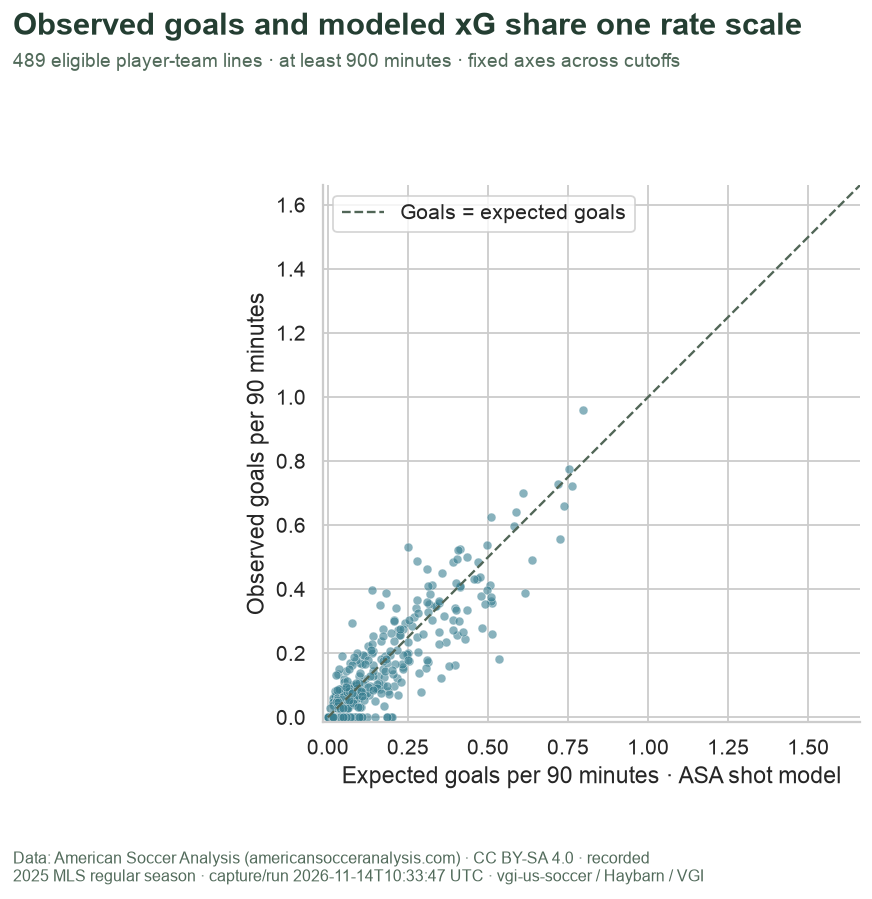

In [9]:
assert len(plot_rows) > 0, "No eligible player-team lines; inspect coverage and lower the cutoff."
fig, ax = plt.subplots(figsize=(10, 7))
lim = float(reference.axis_max.iloc[0]) * 1.08
ax.scatter(
    plot_rows.xg_per90, plot_rows.goals_per90, s=24, alpha=0.6, color="#397f91", edgecolors="white", linewidths=0.3
)
ax.plot([0, lim], [0, lim], color="#516657", linestyle="--", linewidth=1.3, label="Goals = expected goals")
ax.set(
    xlabel="Expected goals per 90 minutes · ASA shot model",
    ylabel="Observed goals per 90 minutes",
    xlim=(-0.015, lim),
    ylim=(-0.015, lim),
    aspect="equal",
)
ax.legend(loc="upper left", frameon=True)
finish(
    fig,
    f"finishing-{MIN_MINUTES}-{DATA_MODE}",
    "Observed goals and modeled xG share one rate scale",
    f"{len(plot_rows)} eligible player-team lines · at least {MIN_MINUTES:,} minutes · fixed axes across cutoffs",
    PROVENANCE,
)

## Inspect the largest positive and negative gaps

Select up to five positive and five negative **goals-minus-xG rates** using deterministic identifier tie-breaks. This intentionally shows extremes, not a representative sample or a forecast. Labels retain the team, and the table keeps minutes and total goals/xG alongside each rate. A positive gap can reflect finishing, chance, model limitations or several factors together.

In [10]:
%%sql extremes <<
WITH ranked AS (
 SELECT *,row_number() OVER(PARTITION BY sign(gap_per90) ORDER BY abs(gap_per90) DESC,player_id,team_id) AS side_rank
 FROM rates WHERE gap_per90 <> 0)
SELECT player_id,team_id,label,minutes_played,goals,round(xgoals,3) AS xgoals,
 round(goals_per90,3) AS goals_per90,round(xg_per90,3) AS xg_per90,gap_per90
FROM ranked WHERE side_rank<=5 ORDER BY gap_per90,player_id,team_id;

,player_id,team_id,label,minutes_played,goals,xgoals,goals_per90,xg_per90,gap_per90
0,XVqKG1XWq0,wvq9B9wQWn,Simon Becher · STL,1472,3,8.721,0.183,0.533,-0.349802
1,9z5k7rej5A,gpMOLwl5zy,Brandon Vázquez · ATX,1734,5,9.868,0.260,0.512,-0.252685
2,9vQ22nALQK,lgpMOvnQzy,Daniel Ríos · VAN,1650,3,7.287,0.164,0.397,-0.233858
3,2vQ1jGzOMr,kRQabn8MKZ,Ola Brynhildsen · TOR,1450,2,5.697,0.124,0.354,-0.229438
4,gjMNrbKMKp,EKXMeX3Q64,Christian Benteke · DCU,2092,9,14.321,0.387,0.616,-0.228902
5,vzqo7EpLqa,kRQand1MKZ,Anthony Markanich · MIN,2087,9,4.242,0.388,0.183,0.205172
6,jYQJ14KyqG,X0Oq66zq6D,Philip Zinckernagel · CHI,2762,15,8.586,0.489,0.280,0.208994
7,0x5gLm2bq7,EKXMeX3Q64,Jackson Hopkins · DCU,920,3,0.760,0.293,0.074,0.219130
8,gpMOogB1Mz,zeQZkL1MKw,Telasco Segovia · MIA,1815,8,2.807,0.397,0.139,0.257499
9,kRQa2AvjMK,NWMWlBK5lz,Evander · CIN,3046,18,8.426,0.532,0.249,0.282888


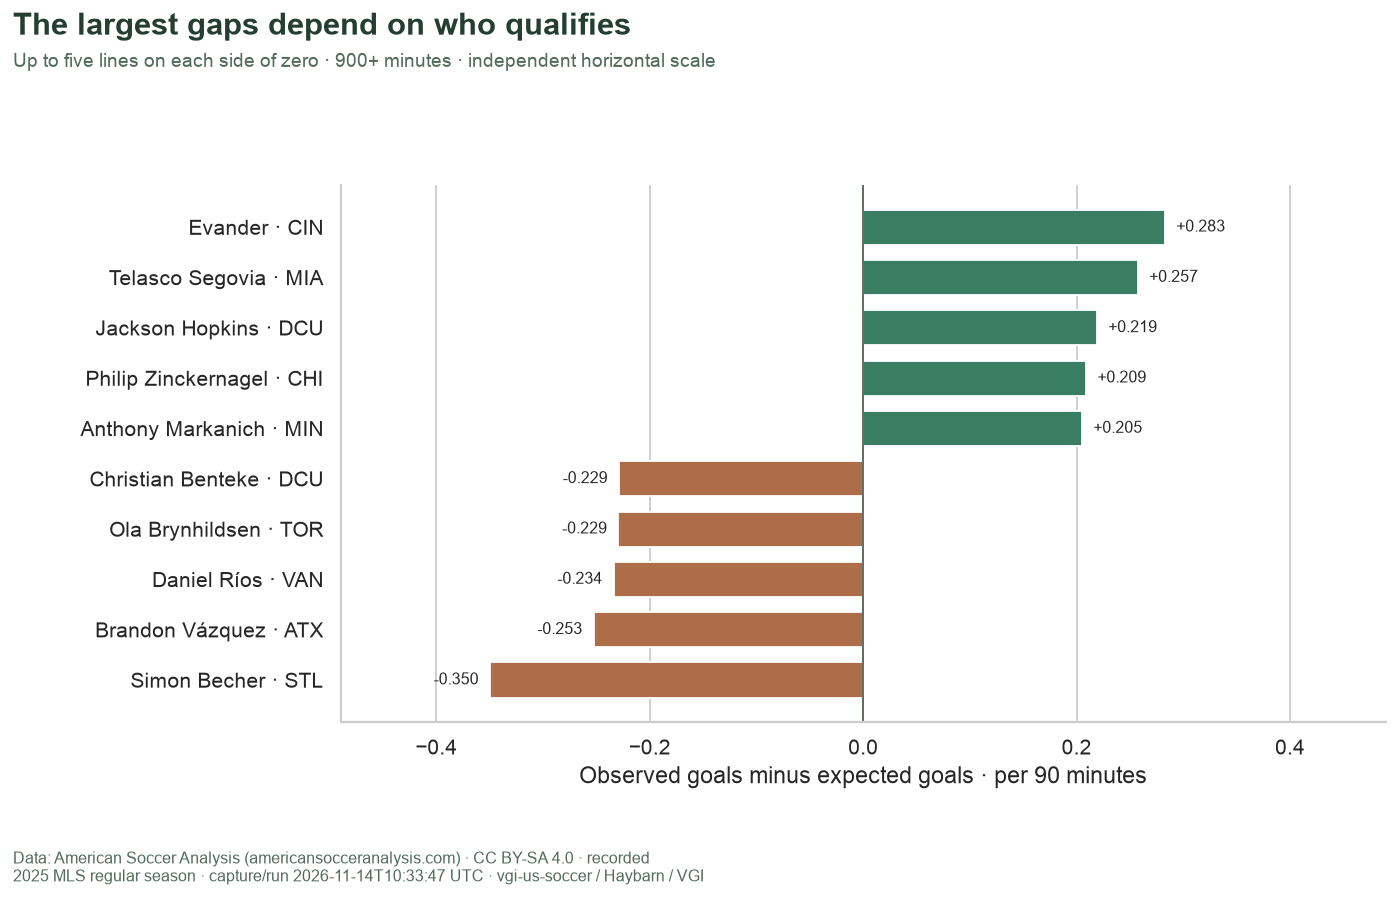

In [11]:
display(extremes)
fig, ax = plt.subplots(figsize=(12, 7))
colors = np.where(extremes.gap_per90 >= 0, "#397d62", "#ac6d48")
ax.barh(extremes.label, extremes.gap_per90, color=colors, height=0.7)
ax.yaxis.grid(False)
ax.axvline(0, color="#516657", linewidth=1)
span = max(abs(extremes.gap_per90).max(), 0.05)
ax.set(xlabel="Observed goals minus expected goals · per 90 minutes", xlim=(-span * 1.4, span * 1.4))
for i, value in enumerate(extremes.gap_per90):
    ax.text(
        value + (span * 0.03 if value >= 0 else -span * 0.03),
        i,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9,
    )
finish(
    fig,
    f"gaps-{MIN_MINUTES}-{DATA_MODE}",
    "The largest gaps depend on who qualifies",
    f"Up to five lines on each side of zero · {MIN_MINUTES:,}+ minutes · independent horizontal scale",
    PROVENANCE,
    left=0.30,
)

In [12]:
%%sql summary <<
SELECT (SELECT count(*) FROM player_lines) AS source_lines,
 (SELECT count(DISTINCT player_id) FROM player_lines) AS source_players,
 count(*) AS eligible_lines,count(DISTINCT player_id) AS eligible_players,
 sum(minutes_played) AS eligible_minutes,sum(goals) AS goals,sum(xgoals) AS xgoals,
 90.0*sum(goals-xgoals)/sum(minutes_played) AS pooled_gap_per90,
 max(gap_per90) AS maximum_gap_per90,min(gap_per90) AS minimum_gap_per90
FROM rates;

In [13]:
display(summary)
s = summary.iloc[0]
display(
    Markdown(
        f"The worker returned **{int(s.source_lines):,} player-team lines** "
        f"for **{int(s.source_players):,} distinct players**. "
        f"At **{MIN_MINUTES:,} minutes**, **{int(s.eligible_lines):,} lines** "
        f"for **{int(s.eligible_players):,} players** qualify. "
        f"Their minutes-weighted aggregate gap is **{s.pooled_gap_per90:+.3f} goals per 90**; "
        "individual gaps range from "
        f"**{s.minimum_gap_per90:+.3f}** to **{s.maximum_gap_per90:+.3f}**. "
        "The pooled rate divides aggregate goals minus aggregate xG by aggregate minutes, then multiplies by 90; "
        "it is not the unweighted mean of player rates. "
        "Changing eligibility changes the population, not the historical observations."
    )
)

,source_lines,source_players,eligible_lines,eligible_players,eligible_minutes,goals,xgoals,pooled_gap_per90,maximum_gap_per90,minimum_gap_per90
0,882,850,489,488,996030.0,1307.0,1433.3241,-0.011414,0.282888,-0.349802


The worker returned **882 player-team lines** for **850 distinct players**. At **900 minutes**, **489 lines** for **488 players** qualify. Their minutes-weighted aggregate gap is **-0.011 goals per 90**; individual gaps range from **-0.350** to **+0.283**. The pooled rate divides aggregate goals minus aggregate xG by aggregate minutes, then multiplies by 90; it is not the unweighted mean of player rates. Changing eligibility changes the population, not the historical observations.

## Check keys, exposure and arithmetic

These checks preserve missing-value semantics and verify the rate conversion and weighted aggregate. ASA publishes rounded xG components; a small absolute tolerance of **0.0002 goals** is used when reconciling its supplied gap with goals minus xG. No test requires a particular player to rank first.

In [14]:
%%sql checks <<
SELECT 'player-team identifiers are unique' AS check_name,
 (SELECT count(*)=count(DISTINCT struct_pack(player:=player_id,team:=team_id)) FROM player_lines) AS passed
UNION ALL SELECT 'key fields are present',(SELECT bool_and(player_id IS NOT NULL AND team_id IS NOT NULL) FROM player_lines)
UNION ALL SELECT 'season and league match request',(SELECT bool_and(season=2025 AND league='mls') FROM player_lines)
UNION ALL SELECT 'classification preserves every line',(SELECT count(*) FROM assessed)=(SELECT count(*) FROM player_lines)
UNION ALL SELECT 'eligible rows meet exposure cutoff',(SELECT bool_and(minutes_played>0 AND minutes_played>={{ MIN_MINUTES }}) FROM rates)
UNION ALL SELECT 'eligible measurements are present',(SELECT bool_and(goals IS NOT NULL AND xgoals IS NOT NULL) FROM rates)
UNION ALL SELECT 'goals and xG are nonnegative',(SELECT bool_and(goals>=0 AND xgoals>=0) FROM rates)
UNION ALL SELECT 'per-90 goals invert to source totals',(SELECT bool_and(abs(goals_per90*minutes_played/90-goals)<1e-9) FROM rates)
UNION ALL SELECT 'per-90 xG inverts to source totals',(SELECT bool_and(abs(xg_per90*minutes_played/90-xgoals)<1e-9) FROM rates)
UNION ALL SELECT 'rate gap equals rate difference',(SELECT bool_and(abs(gap_per90-(goals_per90-xg_per90))<1e-9) FROM rates)
UNION ALL SELECT 'reported ASA gap agrees within rounding',
 (SELECT bool_and(abs(goals_minus_xgoals-(goals-xgoals))<=0.0002) FROM rates WHERE goals_minus_xgoals IS NOT NULL)
UNION ALL SELECT 'weighted mean equals pooled rate',
 (SELECT abs(sum(gap_per90*minutes_played)/sum(minutes_played)-90.0*sum(goals-xgoals)/sum(minutes_played))<1e-9 FROM rates);

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks
if DATA_MODE == "recorded":
    assert sorted(source.requests) == sorted(item["path"] for item in source.manifest["responses"]), source.requests
    assert int(s.source_lines) == source.manifest["responses"][0]["rows"]
display(
    Markdown(
        f"**{len(checks)} SQL checks passed.** "
        + (
            "Recording hashes, row count and the three source requests also passed."
            if DATA_MODE == "recorded"
            else "Official ASA retrieval completed without recorded fallback."
        )
    )
)
Path("validation/source-run.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "minimum_minutes": MIN_MINUTES,
            "source_stamp": SOURCE_STAMP,
            "requests": source.requests,
            "summary": json.loads(summary.to_json(orient="records")),
        },
        indent=2,
    )
    + "\n"
)
plot_rows.to_csv(f"validation/rates-{MIN_MINUTES}-{DATA_MODE}.csv", index=False, lineterminator="\n")

,check_name,passed
0,player-team identifiers are unique,True
1,key fields are present,True
2,season and league match request,True
3,classification preserves every line,True
4,eligible rows meet exposure cutoff,True
5,eligible measurements are present,True
6,goals and xG are nonnegative,True
7,per-90 goals invert to source totals,True
8,per-90 xG inverts to source totals,True
9,rate gap equals rate difference,True


**12 SQL checks passed.** Recording hashes, row count and the three source requests also passed.

## Focused experiment: require twice as many minutes

Change only **`MIN_MINUTES` from `900` to `1800`**, keeping `DATA_MODE = "recorded"`, then restart/run all. Predict fewer eligible player-team lines. Compare the coverage table, the two-sided extremes and the pooled gap. The pooled gap may move in either direction; stricter eligibility does not guarantee better finishing or a smaller absolute gap.

The source table and the scatterplot’s axis scale should remain unchanged. Every retained player-team line must retain identical minutes, goals, xG and rates. A disappearing point is excluded by the rule, not missing from the source. Restore **900** for the default; the README runs the experiment into a separate copy.

In [16]:
connection.close()
source.close()
secrets.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>